# Week 5 - Part D1: the four-variable bubble chart

`health_indicators.csv`, two positions, area and hue, spent in the order the reader has to compare them:

| Channel | Variable | Why this one |
|---|---|---|
| x | `gdp_pc`, log scale | the spread is multiplicative (425×), and GDP is the driver I want read most precisely after access |
| y | `healthcare_access` | the outcome the question is about, 0-100 so the axis has real bounds |
| area | `pop_m` | size is only needed roughly ("big or small country"), and area is read worse than position |
| hue | `region` | identity, not amount: six categories |

All data is synthetic course data for CDB601220 (Week 5).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


from vizlib import PALETTE, save_fig, style_defaults, worst_pair, verdict

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
for p in (CHARTS, SUB):
    p.mkdir(exist_ok=True)
style_defaults()
INK, SOFT, GRID = PALETTE["ink"], PALETTE["ink_soft"], PALETTE["grid"]

hi = pd.read_csv(DATA / "health_indicators.csv")
assert len(hi) == 60 and hi.region.nunique() == 6

## Decisions, checked before drawing

In [2]:
# 1. Size: area proportional to population, sizes from Part B1
SIZE_LO = 6.0
s = SIZE_LO * hi.pop_m / hi.pop_m.min()
SIZES = (s.min(), s.max())
assert np.allclose(s / hi.pop_m, s.iloc[0] / hi.pop_m.iloc[0])
print(f"sizes = ({SIZES[0]:g}, {SIZES[1]:,.0f}) pt² -> area ratio {SIZES[1] / SIZES[0]:.0f}x, diameter ratio {np.sqrt(SIZES[1] / SIZES[0]):.1f}x")

# 2. Hue: six regions. The course palette has three safe slots, so slots 4-6 were picked by testing
#    every all-pairs combination under normal vision and the three CVD simulations (vizlib.worst_pair).
REGIONS = sorted(hi.region.unique())
HUES = ["#0072B2", "#D55E00", "#009E73", "#AA3377", "#332288", "#661100"]
COL = dict(zip(REGIONS, HUES))
for kind in ["normal", "deutan", "protan", "tritan"]:
    i, j, a, b, d = worst_pair(HUES, kind)
    print(f"{kind:>7s}: worst pair {a} / {b}  dE {d:5.1f}  {verdict(d)}")

# 3. The outlier
g = hi.sort_values("gdp_pc", ascending=False)
gap_dec = np.log10(g.gdp_pc.iloc[0]) - np.log10(g.gdp_pc.iloc[1])
print(f"Aldonia ${g.gdp_pc.iloc[0]:,} is {g.gdp_pc.iloc[0] / g.gdp_pc.iloc[1]:.1f}x the next country; on the log axis that is a gap of {gap_dec:.2f} decades")

# 4. What the chart will be claiming
r_all = np.corrcoef(np.log10(hi.gdp_pc), hi.healthcare_access)[0, 1]
r_reg = hi.groupby("region")[["gdp_pc", "healthcare_access"]].apply(lambda d: np.corrcoef(np.log10(d.gdp_pc), d.healthcare_access)[0, 1])
r_pop = hi.pop_m.corr(hi.healthcare_access)
print(f"r(log10 GDP, access) = {r_all:+.2f} overall; inside each region {r_reg.min():+.2f} to {r_reg.max():+.2f}")
print(f"r(population, access) = {r_pop:+.2f}")

sizes = (6, 3,534) pt² -> area ratio 589x, diameter ratio 24.3x
 normal: worst pair #0072B2 / #009E73  dE  18.7  clear
 deutan: worst pair #009E73 / #AA3377  dE  10.3  ok
 protan: worst pair #AA3377 / #332288  dE  11.7  ok
 tritan: worst pair #0072B2 / #009E73  dE   8.4  ok
Aldonia $120,219 is 9.2x the next country; on the log axis that is a gap of 0.97 decades
r(log10 GDP, access) = +0.83 overall; inside each region +0.71 to +0.93
r(population, access) = +0.21


**The outlier decision:** Aldonia ($120,219, 9.2× the next country) stays in. It's a real kind of country (the data dictionary says so), and on a log axis it sits 0.97 decades to the right instead of squashing everyone else into a corner. I label it so nobody mistakes it for an error. Dropping it would hide the one fact a reader most needs about the GDP range.

**Hue:** the worst pair across the three colour-blindness simulations is ΔE 8.4 (tritan, blue vs green) and 10.3 under deuteranopia, all "ok" (above the course's 8 threshold), and the legend sits outside the plot with direct labels on the countries I talk about.

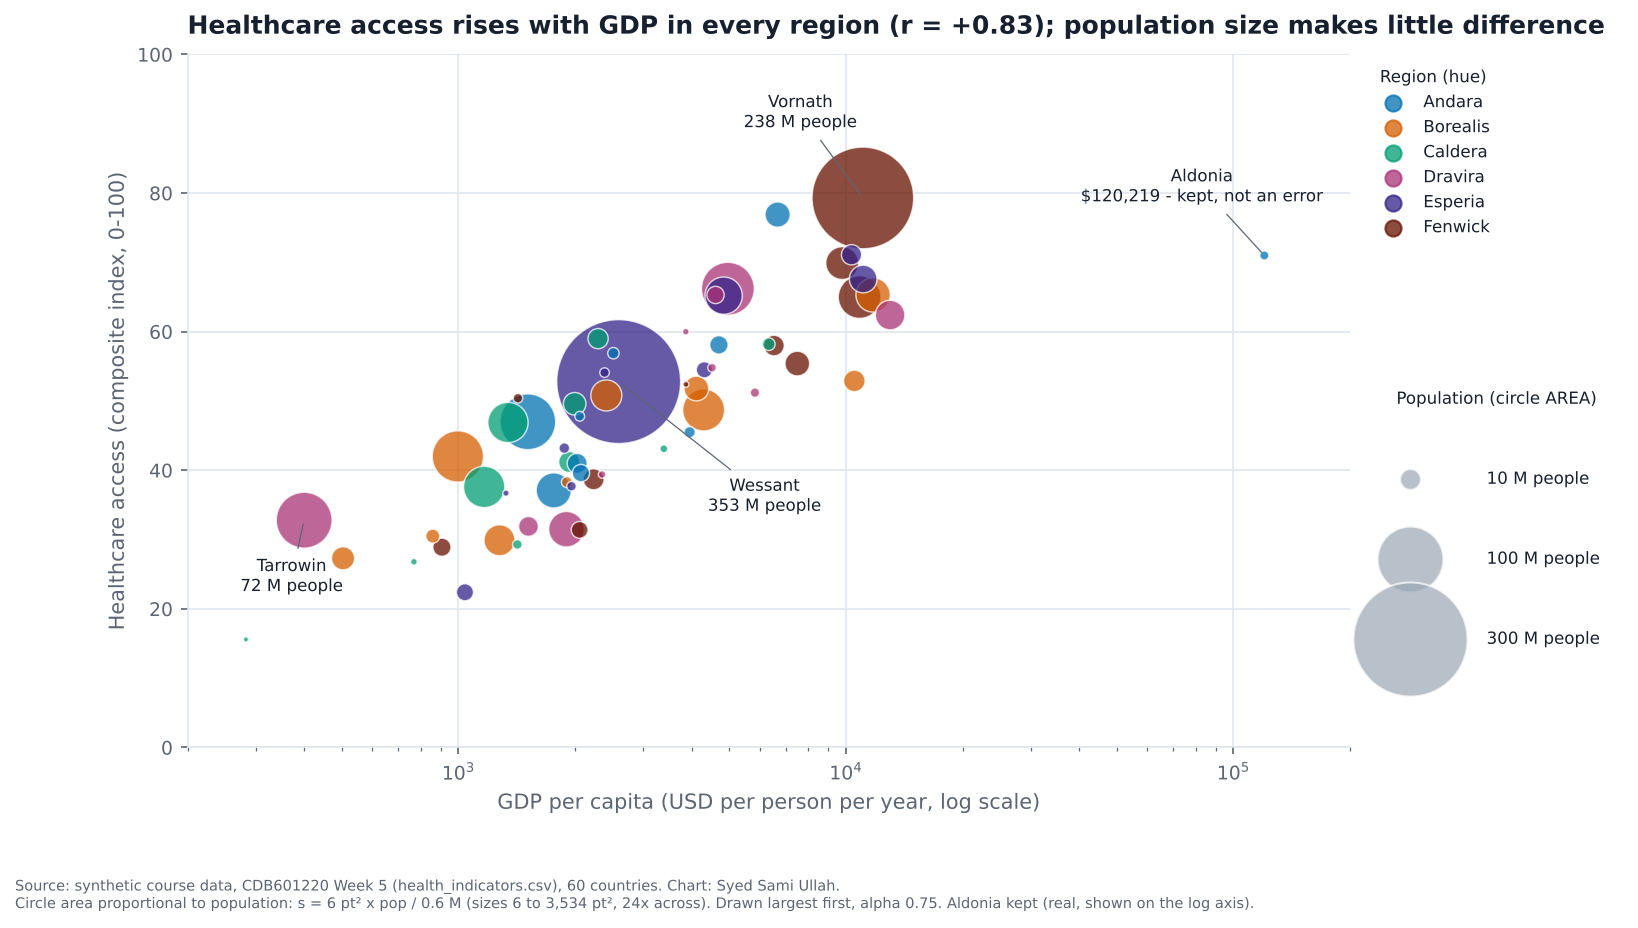

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
order = np.argsort(-s.to_numpy())                     # biggest first, so small countries sit on top
ax.scatter(hi.gdp_pc.iloc[order], hi.healthcare_access.iloc[order], s=s.iloc[order],
           c=hi.region.iloc[order].map(COL), alpha=0.75, edgecolor="white", linewidth=0.7)
ax.set_xscale("log")
ax.set_xlim(200, 200_000)
ax.set_ylim(0, 100)
ax.set_xlabel("GDP per capita (USD per person per year, log scale)")
ax.set_ylabel("Healthcare access (composite index, 0-100)")

labels = {"Wessant": (70, -62), "Vornath": (-30, 34), "Tarrowin": (-6, -34), "Aldonia": (-30, 26)}
for name, off in labels.items():
    rr = hi.set_index("country").loc[name]
    txt = f"{name}\n{rr.pop_m:.0f} M people" if rr.pop_m >= 10 else f"{name}\n${rr.gdp_pc:,.0f} - kept, not an error"
    ax.annotate(txt, (rr.gdp_pc, rr.healthcare_access), xytext=off, textcoords="offset points", fontsize=8, color=INK,
                ha="center", arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.6))

leg1 = ax.legend(handles=[ax.scatter([], [], s=60, color=COL[r_], alpha=0.75, label=r_) for r_ in REGIONS],
                 title="Region (hue)", loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8, title_fontsize=8)
ax.add_artist(leg1)
ref = [10, 100, 300]
ax.legend(handles=[ax.scatter([], [], s=SIZE_LO * v / hi.pop_m.min(), color=PALETTE["muted"], alpha=0.7, edgecolor="white",
                               label=f"{v} M people") for v in ref],
          title="Population (circle AREA)", loc="upper left", bbox_to_anchor=(1.01, 0.56), labelspacing=3.8,
          borderpad=1.4, handletextpad=3.6, fontsize=8, title_fontsize=8)
ax.set_title(f"Healthcare access rises with GDP in every region (r = +{r_all:.2f}); population size makes little difference")
note = (f"Source: synthetic course data, CDB601220 Week 5 (health_indicators.csv), 60 countries. Chart: Syed Sami Ullah.\n"
        f"Circle area proportional to population: s = {SIZE_LO:g} pt² x pop / 0.6 M (sizes {SIZES[0]:g} to {SIZES[1]:,.0f} pt², 24x across). "
        f"Drawn largest first, alpha 0.75. Aldonia kept (real, shown on the log axis).")
save_fig(fig, CHARTS / "partD_bubble.png", note=note)
save_fig(fig, SUB / "partD_bubble.png")
show()

**What this chart shows.** Every region climbs from bottom-left to top-right: richer countries have better healthcare access (r = +0.83 on log GDP, and +0.71 to +0.93 inside each region). Big and small countries are mixed all along that line, so size isn't what separates them. Wessant (353 M) sits right in the middle of the pack, and Aldonia is the rich outlier, kept and labelled.